# Actividad: estilo eruptivo con el conducto 1D estacionario

Modelo de Kozono & Koyaguchi (2009), marchado en diferencias finitas (**no hace falta** `scikits.odes`).

## Qué tienen que hacer

1. **No editen** `RIconduit1D_FD.py`, `RIconduitex5_5.py` ni `RIconduitef5_5.py`.
2. Los datos de cada volcán están en `datos/`. Ahí sí pueden (y deben) escribir.
3. Corran este notebook (Run All). Comenten los gráficos en las celdas de texto que dicen *Comenten aquí*.
4. El caso estromboliano lo **buscan ustedes**: copian la plantilla, rellenan y vuelven a correr.

## Las dos ramas del tiro

El mismo sistema de ecuaciones se cierra de dos maneras:

| Rama | Qué pide en la boca | Típico de |
|---|---|---|
| **explosiva** | gas sónico, o \(P\approx P_\mathrm{atm}\) **con** fragmentación (\(\varphi\ge\varphi_\mathrm{crit}\)) | Pliniana / sub-Pliniana |
| **efusiva** | \(P\approx P_\mathrm{atm}\) **sin** fragmentar (\(\varphi\le\varphi_\mathrm{crit}\)) | lava / domo |

Un mismo volcán puede tener solución explosiva, efusiva, **las dos**, o **ninguna**. Eso también se comenta.

## Y lo estromboliano, ¿cómo entra?

Este modelo es **estacionario**: un perfil \(P(z),\varphi(z),u(z)\) que no cambia en el tiempo. Una erupción estromboliana real es una sucesión de explosiones discretas; **eso no lo resolvemos**.

Lo que sí pueden hacer es buscar datos petrológicos de un volcán estromboliano (Stromboli, Villarrica, Etna, Pacaya, …) y preguntarle al modelo: *¿con estos números el conducto sale fragmentado, como lava, las dos cosas, o ninguna?* Eso es lo que hay que interpretar en los gráficos.


## Cómo usarlo

En una terminal, desde la carpeta del proyecto:

```bash
pip install numpy matplotlib
```

Después abran este archivo y ejecuten **todas** las celdas.

Para cambiar de volcán no toquen el solver: cambian el nombre en `datos/` o copian la plantilla. La llamada es siempre:

```python
from datos import cargar
from RIconduit1D_FD import RIconduit1D_FD_f

volc = cargar("calbuco2015")           # archivo en datos/
out  = RIconduit1D_FD_f(volc, rama="explosiva", verbose=False)
```

`rama` es `"explosiva"` o `"efusiva"`.


In [1]:
%matplotlib inline
import os
import sys
import importlib

import matplotlib.pyplot as plt
import numpy as np

sys.path.insert(0, os.getcwd())

from datos import cargar
from RIconduit1D_FD import RIconduit1D_FD_f
from calbuco2015d import Patm, geometry as geometry_default


def resumen(volc, rama, out):
    z, sol = out[0], out[1]
    v, rho_ti, phicrit = out[3], out[7], out[9]
    wr = float(volc.radius1)
    geom = getattr(volc, "geometry", geometry_default)
    if geom == "dyke":
        Q = v * wr * float(getattr(volc, "dl", 100.0))
    else:
        Q = v * np.pi * wr ** 2
    Pex, phiex, um, ug = sol[-1, 0], sol[-1, 1], sol[-1, 4], sol[-1, 5]
    frag = np.where(sol[:, 1] > phicrit + 1e-3)[0]
    zfrag = z[frag[0]] if frag.size else np.nan
    if rama == "efusiva":
        ok = (
            abs(Pex - Patm) < 0.05e5
            and z[-1] > -2.0
            and phiex <= phicrit
        )
    else:
        ok = z[-1] >= -15.0 and (
            (phiex >= phicrit) or abs(Pex - Patm) < 1.5e5
        )
    nombre = getattr(volc, "nombre", "?")
    print(f"{nombre}  |  rama {rama}  |  {'solución' if ok else 'sin solución estricta'}")
    print(f"  vinicial = {v:.4f} m/s")
    print(f"  Q        = {Q * rho_ti:.3e} kg/s")
    print(f"  z_boca   = {z[-1]:.2f} m")
    print(f"  P_boca   = {Pex/1e5:.2f} bar   (P_atm = {Patm/1e5:.2f} bar)")
    print(f"  φ_boca   = {phiex:.3f}   (φ_crit = {phicrit:.3f})")
    print(f"  um, ug   = {um:.2f}, {ug:.2f} m/s")
    if frag.size:
        print(f"  fragmenta en z = {zfrag/1e3:.2f} km")
    else:
        print("  no fragmenta")
    return ok


def figura_6(volc, rama, out, color="C0"):
    z, sol = out[0], out[1]
    visc, phicrit = out[6], out[9]
    P, phi, Nd, x_cr, um, ug = (sol[:, i] for i in range(6))
    nombre = getattr(volc, "nombre", "")
    fig, axs = plt.subplots(1, 6, figsize=(18, 6), sharey=True)
    fig.suptitle(f"{nombre}  —  rama {rama}", fontsize=13)
    axs[0].semilogx(P, z, linewidth=2, color=color)
    axs[0].axvline(Patm, color="k", ls=":", lw=0.8)
    axs[0].set_xlabel("Pressure (Pa)", fontweight="bold")
    axs[0].set_ylabel("Depth (m)", fontweight="bold")
    axs[1].plot(phi, z, linewidth=2, color=color)
    axs[1].axvline(phicrit, color="k", ls="--", lw=0.8)
    axs[1].set_xlabel("gas volume fraction", fontweight="bold")
    axs[2].semilogx(um, z, label="velocity liq", linewidth=2, color="C0")
    axs[2].semilogx(ug, z, "--", label="velocity gas", linewidth=2, color="C1")
    axs[2].set_xlabel("velocity (m/s)", fontweight="bold")
    axs[2].legend(fontsize=8)
    axs[3].plot(Nd, z, linewidth=2, color=color)
    axs[3].set_xlabel("Nd", fontweight="bold")
    axs[4].plot(x_cr, z, linewidth=2, color=color)
    axs[4].set_xlabel("crystal content", fontweight="bold")
    axs[5].semilogx(visc, z, linewidth=2, color=color)
    axs[5].set_xlabel("viscosity (Pa.s)", fontweight="bold")
    for ax in axs:
        ax.set_ylim(z.min(), max(z.max(), 0))
        ax.grid(True, alpha=0.3)
    fig.tight_layout()
    plt.show()


## 1. Erupción explosiva — Calbuco 2015

Datos **dados** en `datos/calbuco2015.py` (no los busquen). Corran la rama explosiva.

En los gráficos fíjense en:

- dónde cruza \(\varphi\) a \(\varphi_\mathrm{crit}\) (profundidad de fragmentación);
- si \(u_g\) se separa de \(u_m\) después de fragmentar;
- \(P\) en la boca frente a \(P_\mathrm{atm}\);
- el orden de magnitud del flujo de masa.


Calbuco 2015 | estilo observado: sub-Pliniana / explosiva
  H2O = 4 wt%   T = 970 °C   R = 16 m   ΔP = 5.0 MPa


Calbuco 2015  |  rama explosiva  |  solución
  vinicial = 18.5437 m/s
  Q        = 3.674e+07 kg/s
  z_boca   = 0.00 m
  P_boca   = 12.98 bar   (P_atm = 1.01 bar)
  φ_boca   = 0.921   (φ_crit = 0.580)
  um, ug   = 226.70, 777.31 m/s
  fragmenta en z = -1.28 km


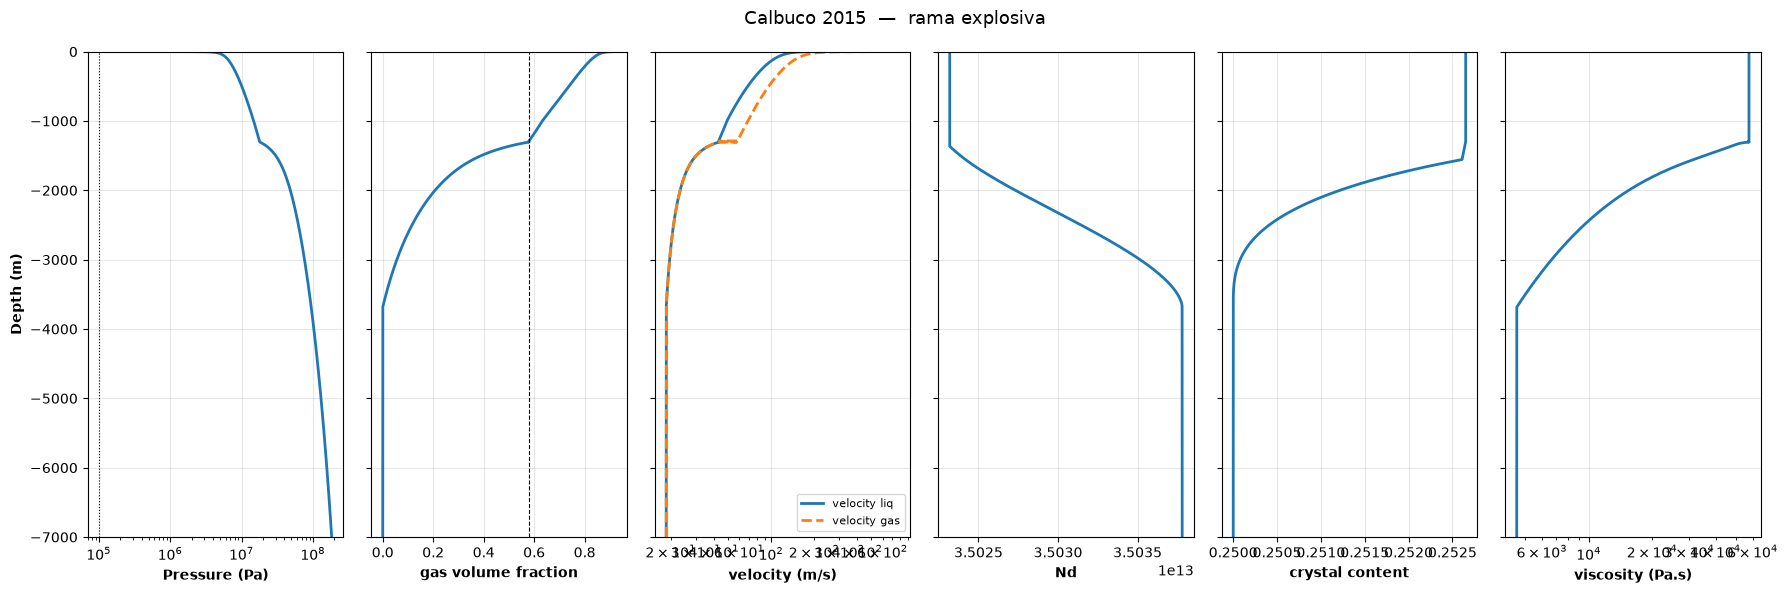

In [2]:
calbuco = cargar("calbuco2015")
print(calbuco.nombre, "| estilo observado:", calbuco.estilo_obs)
print(f"  H2O = {calbuco.h2o1} wt%   T = {calbuco.T1-273.15:.0f} °C   R = {calbuco.radius1} m   ΔP = {calbuco.overP1/1e6:.1f} MPa")

out_cal_ex = RIconduit1D_FD_f(calbuco, rama="explosiva", verbose=False)
ok_cal = resumen(calbuco, "explosiva", out_cal_ex)
figura_6(calbuco, "explosiva", out_cal_ex, color="C0")


**Comenten aquí (Calbuco, explosiva).** ¿A qué profundidad fragmenta? ¿Las velocidades se separan? ¿El flujo de masa es alto o bajo comparado con una lava? ¿La boca queda sónica o solo despresurizada?


## 2. Erupción efusiva — St. Helens 2004 (domo)

Datos **dados** en `datos/sthelens2004.py`. Corran la rama **efusiva**. Si quieren, corran también la explosiva para ver si existe.

Comparen con Calbuco: \(\varphi\) vs \(\varphi_\mathrm{crit}\), \(u_m\) y \(u_g\), \(P\) de salida, \(Q\).


St. Helens 2004 | estilo observado: domo / efusiva
  H2O = 3.0 wt%   T = 950 °C   R = 12.11 m   ΔP = 16.2 MPa


St. Helens 2004  |  rama efusiva  |  sin solución estricta
  vinicial = 0.0554 m/s
  Q        = 5.937e+04 kg/s
  z_boca   = -0.61 m
  P_boca   = 57.54 bar   (P_atm = 1.01 bar)
  φ_boca   = 0.745   (φ_crit = 0.745)
  um, ug   = 0.21, 0.35 m/s
  no fragmenta


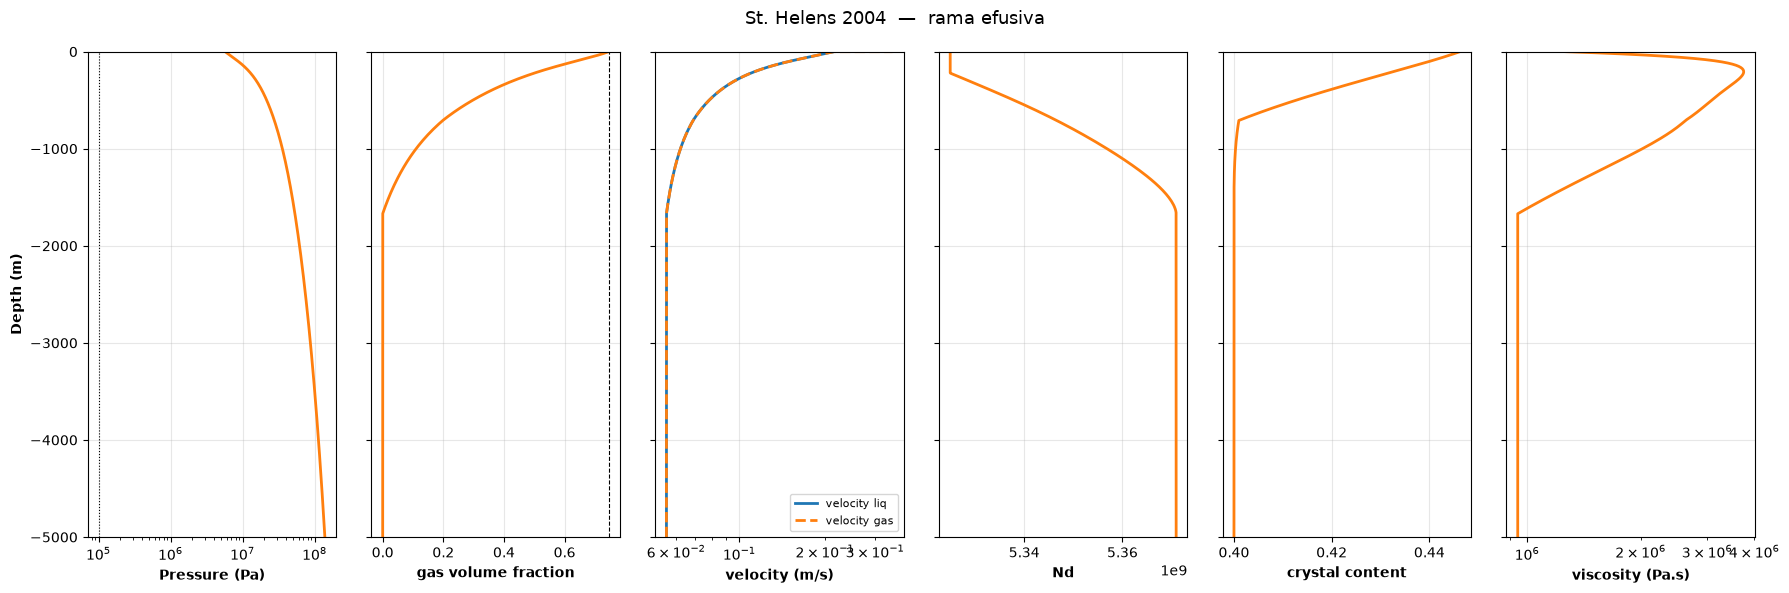

St. Helens 2004  |  rama explosiva  |  sin solución estricta
  vinicial = 0.1001 m/s
  Q        = 1.073e+05 kg/s
  z_boca   = -576.60 m
  P_boca   = 54.51 bar   (P_atm = 1.01 bar)
  φ_boca   = 0.754   (φ_crit = 0.754)
  um, ug   = 0.40, 0.66 m/s
  no fragmenta


np.False_

In [3]:
sthelens = cargar("sthelens2004")
print(sthelens.nombre, "| estilo observado:", sthelens.estilo_obs)
print(f"  H2O = {sthelens.h2o1} wt%   T = {sthelens.T1-273.15:.0f} °C   R = {sthelens.radius1} m   ΔP = {sthelens.overP1/1e6:.1f} MPa")

out_sh_ef = RIconduit1D_FD_f(sthelens, rama="efusiva", verbose=False)
resumen(sthelens, "efusiva", out_sh_ef)
figura_6(sthelens, "efusiva", out_sh_ef, color="C1")

out_sh_ex = RIconduit1D_FD_f(sthelens, rama="explosiva", verbose=False)
resumen(sthelens, "explosiva", out_sh_ex)


**Comenten aquí (St. Helens, efusiva).** ¿Fragmenta? ¿\(u_g\) se parece a \(u_m\)? ¿El tiro llega a \(P_\mathrm{atm}\) o se queda corto? Si la rama explosiva no llega a la boca, ¿qué significa eso para el estilo?


## 3. Caso estromboliano — lo buscan ustedes

Este modelo **no** calcula las explosiones de Stromboli. Calcula un estado estacionario. La pregunta es: con datos reales de un volcán estromboliano, ¿qué rama(s) aparecen?

### Pasos

1. Copien `datos/plantilla_estromboliana.py` a `datos/mi_estromboliana.py`.
2. Rellenen solo lo marcado con `# BUSCAR` (composición del vidrio, H₂O, T, cristales, profundidad de cámara, radio o dique, sobrepresión).
3. Si el magma es basáltico (\(\mathrm{SiO}_2 \lesssim 57\) wt%), descomenten `C1` y `beta` basálticos en la plantilla.
4. Pongan `LISTO = True` y citen las fuentes (paper, tabla, página).
5. Vuelvan a ejecutar las celdas de abajo.

Volcanes razonables: **Stromboli**, **Villarrica**, **Etna**, **Pacaya**. Sobrepresión y radio casi nunca salen en un abstract: si no los encuentran, elijan un valor en el rango de la plantilla y **justifiquen**.

Referencia útil del curso: Castruccio, Rebolledo & Gómez (2025), *JGR Solid Earth* (Villarrica aparece como hawaiana/estromboliana).


In [4]:
VOLCAN_ESTROMBOLIANA = "mi_estromboliana"  # nombre del archivo en datos/, sin .py

est = None
try:
    est = importlib.import_module(f"datos.{VOLCAN_ESTROMBOLIANA}")
except ImportError:
    print(
        f"Todavía no existe datos/{VOLCAN_ESTROMBOLIANA}.py.\n"
        "Copien datos/plantilla_estromboliana.py a ese nombre, rellenen y pongan LISTO = True."
    )
else:
    if not getattr(est, "LISTO", False):
        print(f"{VOLCAN_ESTROMBOLIANA}: LISTO = False. Rellenen los # BUSCAR y cámbienlo a True.")
        est = None
    else:
        print(est.nombre, "| estilo observado:", getattr(est, "estilo_obs", "?"))
        print(f"  H2O = {est.h2o1} wt%   T = {est.Tc1} °C   R = {est.radius1} m")


Todavía no existe datos/mi_estromboliana.py.
Copien datos/plantilla_estromboliana.py a ese nombre, rellenen y pongan LISTO = True.


In [5]:
if est is None:
    print("Saltando el caso estromboliano (falta el archivo o LISTO = False).")
else:
    print("--- rama explosiva ---")
    out_st_ex = RIconduit1D_FD_f(est, rama="explosiva", verbose=False)
    resumen(est, "explosiva", out_st_ex)
    figura_6(est, "explosiva", out_st_ex, color="C0")

    print("--- rama efusiva ---")
    out_st_ef = RIconduit1D_FD_f(est, rama="efusiva", verbose=False)
    resumen(est, "efusiva", out_st_ef)
    figura_6(est, "efusiva", out_st_ef, color="C1")


Saltando el caso estromboliano (falta el archivo o LISTO = False).


**Comenten aquí (estromboliana).** ¿Qué volcán eligieron y de dónde salieron los datos? ¿El modelo da rama explosiva, efusiva, ambas o ninguna? ¿Eso calza con el estilo observado, o el modelo estacionario se queda corto? Si cambiaron radio o ΔP porque no los encontraron, ¿hacia qué lado mueve el resultado?


## 4. Comparación

Completen (una frase cada uno):

- Calbuco vs St. Helens: la diferencia más clara en los perfiles es …
- En este modelo, “estromboliano” se ve como …
- Una limitación del 1D estacionario para el caso 3 es …
